In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
from tqdm import tqdm

from maple_fep.utils import fit_sklearn_gmm, select_gmm_components


/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Read data

In [2]:
# This notebook demonstrates how to fit a GMM on FEP data.
# For the seven canonical benchmarks (cdk8, pfkfb3, tnks2, cmet, eg5, syk, openfe),
# pre-fitted parameters are already shipped in maple_fep.models.presets:
#     from maple_fep.models.presets import get_preset
#     preset = get_preset("openfe")
file_path = "data/cmet_benchmark.csv"
data = pd.read_csv(file_path)
data


,Unnamed: 0,Source,Destination,Experimental DeltaDeltaG,DeltaDeltaG,DeltaDeltaG Error,CCC,CCC Error,Dataset,Sampling Time,MLE,MAP,VI,VI_uncertainty,GMVI,GMVI_uncertainty,Outlier Probability
0,0,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402744_300,1.96,2.43,0.09,2.53,1.03,cmet,20ns,2.528261,1.744626,1.740224,0.532852,1.156918,1.023947,0.148792
1,1,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402745_200,1.72,1.44,0.07,1.63,1.38,cmet,20ns,1.626078,1.018753,1.017543,0.514106,1.109611,0.658146,0.051365
2,2,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402743_42,0.79,0.48,0.07,0.82,1.24,cmet,20ns,0.823718,1.078870,1.074561,0.489439,0.897311,0.607924,0.052979
3,3,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402764_90,1.25,1.31,0.06,0.94,1.38,cmet,20ns,0.937768,0.942715,0.939614,0.583311,0.840211,0.555849,0.054490
4,4,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402760_1,-1.42,-1.90,0.11,-2.32,1.29,cmet,20ns,-2.318293,-1.485225,-1.488140,0.551901,-0.537194,0.760101,0.201631
5,5,CHEMBL3402765_11-charged-pKa-8.1,CHEMBL3402742_23,0.44,-1.07,0.10,-0.91,1.29,cmet,20ns,-0.907508,-0.599900,-0.599429,0.534472,-0.320513,0.533571,0.064114
6,6,CHEMBL3402753_200,CHEMBL3402747_3400,1.68,3.52,0.05,3.92,0.62,cmet,20ns,3.915796,2.974536,2.966073,0.589516,1.410718,0.727064,0.386812
7,7,CHEMBL3402753_200,CHEMBL3402761_1,-3.14,-1.78,0.12,-2.34,0.62,cmet,20ns,-2.339109,-1.259029,-1.262725,0.603806,0.048886,0.991932,0.363317
8,8,CHEMBL3402753_200,CHEMBL3402755_4200,1.80,1.61,0.03,1.53,0.54,cmet,20ns,1.525578,1.401975,1.395727,0.637322,1.271742,0.956128,0.055274
9,9,CHEMBL3402753_200,CHEMBL3402750_400,0.41,0.45,0.04,0.70,0.32,cmet,20ns,0.697742,0.034617,0.025473,0.634485,0.095888,0.670615,0.056590


# 2. Get node/edge values
### Nodes need to be zero-centered first

In [3]:
data_1d = data['Experimental DeltaDeltaG'].values.flatten()
data_1d = data_1d - np.mean(data_1d)  # zero-center
print('mean of data: ', np.mean(data_1d))
print('variance of data: ', np.var(data_1d, axis=0))
data_1d.shape


mean of data:  -4.5285412846552437e-17
variance of data:  2.9065372114496766


(57,)

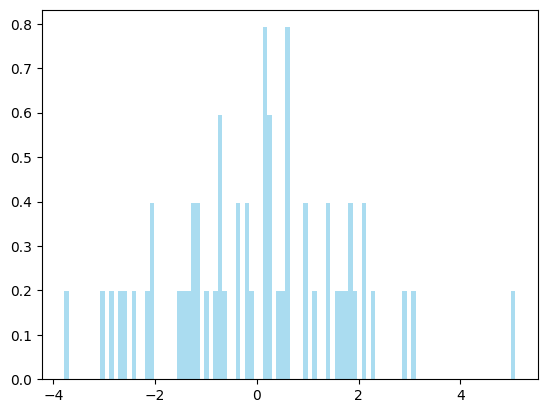

In [4]:
## Visualize histogram of data
plt.hist(data_1d, bins=100, density=True, alpha=0.7, color='skyblue')
plt.show()

## Example: Fit a GMM with three components

In [5]:
k = 3
params = fit_sklearn_gmm(data_1d, n_components=k, random_state=42)
means = np.asarray(params.means)
covariances = np.asarray(params.variances)
weights = np.asarray(params.weights)
means, covariances, weights


(array([-2.40298859,  1.52847341, -0.22595261]),
 array([0.54472338, 1.7395939 , 0.82598576]),
 array([0.1718697, 0.3420601, 0.4860702]))

# 3. Use Cross-Validation to get best k (number of GMM components)

In [6]:
k_values = [2, 3, 4, 5, 6, 7, 8]

selection = select_gmm_components(
    data_1d,
    k_values=k_values,
    test_size=0.2,
    random_state=42,
)

for k, score in zip(selection.k_values, selection.cv_scores):
    print(f'k={k:2d}, test_log_likelihood={score:.4f}')

print(f'\nBest model: k={selection.best_k}, test_log_likelihood={selection.best_score:.4f}')


k= 2, test_log_likelihood=-1.8148
k= 3, test_log_likelihood=-1.9504
k= 4, test_log_likelihood=-1.8719
k= 5, test_log_likelihood=-2.4364
k= 6, test_log_likelihood=-2.0510
k= 7, test_log_likelihood=-4.9446
k= 8, test_log_likelihood=-2.4005

Best model: k=2, test_log_likelihood=-1.8148


means:  [-1.25257708  0.82946548]
variances:  [1.55454709 2.07485395]
weights:  [0.39839026 0.60160974]


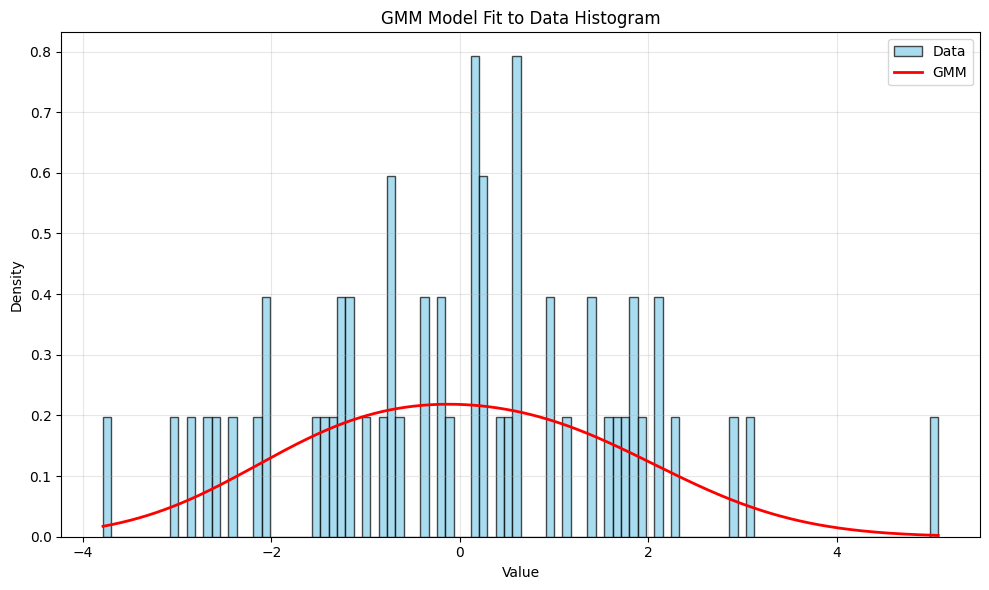

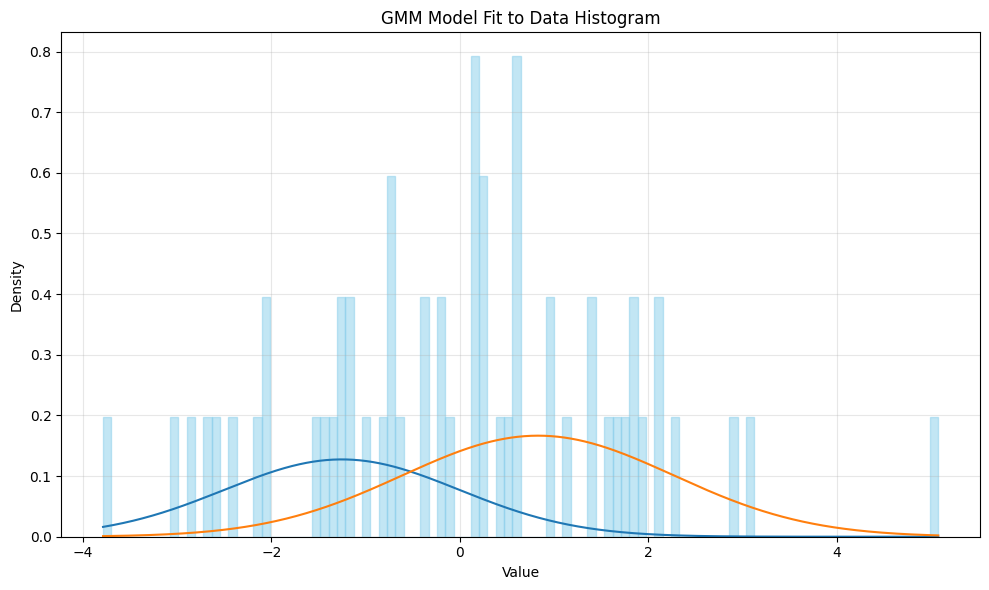

In [7]:
# Refit on the full dataset with the selected K
k = selection.best_k
params = fit_sklearn_gmm(data_1d, n_components=k, random_state=42)
means = np.asarray(params.means)
covariances = np.asarray(params.variances)
weights = np.asarray(params.weights)

print('means: ', means)
print('variances: ', covariances)
print('weights: ', weights)


### Visualizing the GMM model
min_val = data_1d.min()
max_val = data_1d.max()
x = np.linspace(min_val, max_val, 1000)
y_all = np.zeros_like(x)
for i in range(k):
    std = np.sqrt(covariances[i])
    y_component = scipy.stats.norm.pdf(x, means[i], std)
    y_all += weights[i] * y_component

plt.figure(figsize=(10, 6))
plt.hist(data_1d, label="Data", density=True, bins=100,
         alpha=0.7, color='skyblue', edgecolor='black')
plt.plot(x, y_all, label="GMM", linewidth=2, color='red')
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("GMM Model Fit to Data Histogram")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



plt.figure(figsize=(10, 6))
for i in range(k):
    std = np.sqrt(covariances[i])
    y_component = scipy.stats.norm.pdf(x, means[i], std)
    plt.plot(x, weights[i] * y_component, label=f"Component {i}")
plt.hist(data_1d, label="Data", density=True, bins=100,
         alpha=0.5, color='skyblue', edgecolor='skyblue')
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("GMM Model Fit to Data Histogram")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
